# **15.  Máquinas de soporte vectorial con más de dos clases.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

## 15.3 Un problema multiclase: Wine.

In [82]:
wine = load_wine()

X = wine.data
y = wine.target

In [83]:
wine.feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [84]:
wine.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [85]:
wine.DESCR

'.. _wine_dataset:\n\nWine recognition dataset\n------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 178\n:Number of Attributes: 13 numeric, predictive attributes and the class\n:Attribute Information:\n    - Alcohol\n    - Malic acid\n    - Ash\n    - Alcalinity of ash\n    - Magnesium\n    - Total phenols\n    - Flavanoids\n    - Nonflavanoid phenols\n    - Proanthocyanins\n    - Color intensity\n    - Hue\n    - OD280/OD315 of diluted wines\n    - Proline\n    - class:\n        - class_0\n        - class_1\n        - class_2\n\n:Summary Statistics:\n\n============================= ==== ===== ======= =====\n                                Min   Max   Mean     SD\n============================= ==== ===== ======= =====\nAlcohol:                      11.0  14.8    13.0   0.8\nMalic Acid:                   0.74  5.80    2.34  1.12\nAsh:                          1.36  3.23    2.36  0.27\nAlcalinity of Ash:            10.6  30.0    19.5   3.3\nMagnesium:      

In [86]:
X.shape

(178, 13)

## 15.4 Exploración inicial.

In [87]:
datos = pd.DataFrame(
    X, columns= wine.feature_names
)

datos["Clase"] = y
datos.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [88]:
datos["Clase"].value_counts().sort_index()

Clase
0    59
1    71
2    48
Name: count, dtype: int64

## 15.5 Las variables no están en la misma escala.

In [89]:
datos.drop(columns="Clase").describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


## 15.6 Separación en entrenamiento y prueba.

In [90]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state=42, stratify=y
)

In [91]:
X_train.shape

(133, 13)

In [92]:
X_test.shape

(45, 13)

## 15.8 Multiclase en SVC.

In [93]:
modelo = Pipeline(
    [
        ("Scaler", StandardScaler()),
        ("svc", SVC(kernel="linear", C = 1))
    ]
)

modelo.fit(X_train, y_train)

pred_train = modelo.predict(X_train)

accuracy_score(y_train, pred_train)

1.0

## 15.10 Validación cruzada.

In [94]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [95]:
score = cross_val_score(
    modelo,
    X_train,
    y_train,
    cv = cv,
    scoring= "accuracy"
)

In [96]:
score

array([0.96296296, 0.96296296, 1.        , 0.96153846, 1.        ])

In [97]:
score.mean()

np.float64(0.9774928774928775)

In [98]:
score.std()

np.float64(0.01838434849561446)

## 15.11 Selección manual de 𝐶.

In [99]:
valores_C = [
    0.001, 0.01, 1, 10, 100
]

In [100]:
resultados_C = []

for C in valores_C:
    modelo_C = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "linear", C = C))
    ])

    scores = cross_val_score(modelo_C, X_train, y_train, cv = cv, scoring = "accuracy")
    resultados_C.append({
        "C": C,
        "Accuracy_CV": scores.mean(),
        "SD_CV": scores.std()
    })

resultados_C = pd.DataFrame(resultados_C)

resultados_C

,C,Accuracy_CV,SD_CV
0,0.001,0.398575,0.018691
1,0.010,0.985185,0.029630
2,1.000,0.977493,0.018384
3,10.000,0.977493,0.018384
4,100.000,0.977493,0.018384


## 15.12 Automatizando la búsqueda con GridSearchCV.

In [101]:
pipeline = Pipeline(
    [
        ("Scaler", StandardScaler()),
        ("svc", SVC(kernel="linear"))
    ]
)

malla = {
    "svc__C": [0.001, 0.01, 1, 10, 100]
}

## 15.13 Una cuadrícula sencilla.

In [102]:
grid_lineal = GridSearchCV(
    estimator=pipeline,
    param_grid=malla,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

In [103]:
grid_lineal.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...l='linear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informat

## 15.14 Resultados de GridSearchCV.

In [104]:
grid_lineal.best_params_

{'svc__C': 0.01}

In [105]:
grid_lineal.best_score_

np.float64(0.9851851851851852)

In [106]:
pipeline = Pipeline(
    [
        ("Scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf"))
    ]
)

## 15.15 ¿Qué ocurre con el kernel RBF?

In [107]:
param_grid_rbf = {
    "svc__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],
    "svc__gamma": [
        0.001,
        0.01,
        0.1,
        1,
        10
    ]
}

grid_rbf = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid_rbf,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

grid_rbf.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.01, 0.1, ...], 'svc__gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

In [108]:
grid_rbf.best_params_

{'svc__C': 1, 'svc__gamma': 0.1}

In [109]:
grid_rbf.best_score_

np.float64(0.9925925925925926)

## 15.18 ¿Podemos comparar diferentes kernels?

In [110]:
malla_grande = [
    {
        "svc__kernel": ["linear"],
        "svc__C": [
                0.01,
                0.1,
                1,
                10,
                100
            ]  
    },

    {
        "svc__kernel": ["rbf"],
        "svc__C": [
                0.01,
                0.1,
                1,
                10,
                100
            ],
        "svc__gamma": [
                0.001,
                0.01,
                0.1,
                1,
                10
            ]  
    },

    {
        "svc__kernel": ["poly"],
        "svc__C": [0.1, 1, 10],
        "svc__degree": [2,3,4],
        "svc__gamma": ["scale"],
        "svc__coef0": [1]
    }
]

In [111]:
pipeline = Pipeline(
    [
        ("Scaler", StandardScaler()),
        ("svc", SVC())
    ]
)

## 15.19 Búsqueda conjunta.

In [112]:
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=malla_grande,
    cv=cv,
    scoring="accuracy",
    n_jobs=1,
    return_train_score=True
)

In [113]:
grid.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'svc__C': [0.01, 0.1, ...], 'svc__kernel': ['linear']}, {'svc__C': [0.01, 0.1, ...], 'svc__gamma': [0.001, 0.01, ...], 'svc__kernel': ['rbf']}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_

In [114]:
grid.best_score_

np.float64(0.9925925925925926)

In [115]:
grid.best_params_

{'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}

## 15.20 El mejor estimador.

In [116]:
mejor_modelo = grid.best_estimator_
mejor_modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [117]:
mejor_svc = (mejor_modelo.named_steps["svc"])
mejor_svc.n_support_

array([17, 29, 20], dtype=int32)

In [118]:
score_train = cross_val_score(
    mejor_modelo,
    X_train,
    y_train,
    cv = cv,
    scoring= "accuracy"
)

In [119]:
score_train.mean()

np.float64(0.9925925925925926)

In [120]:
score_test = cross_val_score(
    mejor_modelo,
    X_test,
    y_test,
    cv = cv,
    scoring= "accuracy"
)

score_test.mean()

np.float64(0.9555555555555555)

## 15.22 Inspeccionando los resultados de la búsqueda.

In [121]:
resultados_grid = pd.DataFrame(
    grid.cv_results_
)

In [122]:
columnas = [
    "param_svc__kernel",
    "param_svc__C",
    "param_svc__gamma",
    "param_svc__degree",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

resultados_resumen = (
    resultados_grid[columnas]
    .sort_values("rank_test_score")
)

resultados_resumen.head(15)

,param_svc__kernel,param_svc__C,param_svc__gamma,param_svc__degree,mean_train_score,mean_test_score,std_test_score,rank_test_score
27,rbf,100.00,0.1,NaN,1.000000,0.992593,0.014815,1
31,poly,0.10,scale,3.0,1.000000,0.992593,0.014815,1
22,rbf,10.00,0.1,NaN,1.000000,0.992593,0.014815,1
17,rbf,1.00,0.1,NaN,1.000000,0.992593,0.014815,1
0,linear,0.01,NaN,NaN,0.984976,0.985185,0.029630,5
35,poly,1.00,scale,4.0,1.000000,0.985185,0.029630,5
34,poly,1.00,scale,3.0,1.000000,0.985185,0.029630,5
32,poly,0.10,scale,4.0,1.000000,0.985185,0.029630,5
37,poly,10.00,scale,3.0,1.000000,0.985185,0.029630,5
38,poly,10.00,scale,4.0,1.000000,0.985185,0.029630,5


## 15.24 OvO y OvR en la práctica.

In [123]:
from sklearn.multiclass import OneVsRestClassifier

In [124]:
modelo_ovr = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", OneVsRestClassifier(SVC(kernel = "linear", C = 1)))
])

In [125]:
scores_ovr = cross_val_score(modelo_ovr, X_train, y_train, cv = cv, scoring="accuracy")


In [126]:
scores_ovr

array([0.96296296, 0.96296296, 1.        , 0.96153846, 1.        ])

In [127]:
scores_ovr.mean()

np.float64(0.9774928774928775)

In [128]:
scores_ovr.std()

np.float64(0.01838434849561446)

## Ejercicios

**15.25.1 Ejercicio 1. Cambiar el número de pliegues.** Repite la evaluación del modelo lineal utilizando validación cruzada estratificada (StratifiedKFold) con:

- k = 3 pliegues (n_splits=3).
- k = 10 pliegues (n_splits=10).

Para cada caso, calcula el promedio y la desviación estándar de accuracy.

In [129]:

modelo_lineal = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="linear",
            C=1
        )
    )
])

modelo_lineal.fit(
    X_train,
    y_train
)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [130]:
cv1 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv2 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scores1 = cross_val_score(
    modelo_lineal,
    X_train,
    y_train,
    cv=cv1,
    scoring="accuracy"
)

scores2 = cross_val_score(
    modelo_lineal,
    X_train,
    y_train,
    cv=cv2,
    scoring="accuracy"
)

In [132]:
tabla_resultado1 = {
    "K": [3, 10],
    "Accuracy_CV": [scores1.mean(), scores2.mean()],
    "SD_CV": [scores1.std(), scores2.std()]
}

tabla_resultado1 = pd.DataFrame(
    tabla_resultado1
)

tabla_resultado1


,K,Accuracy_CV,SD_CV
0,3,0.955387,0.047928
1,10,0.970330,0.048414



Preguntas:

- ¿Qué porcentaje de los datos se utiliza para entrenamiento y validación en cada iteración?

    **R:** Para k=3, se ocupó $33.3\%$ de los datos para validación y un $66.7\%$ para el entrenamiento en cada iteración; en cambio, para k=10, los porcentajes fueron $10\%$ y $90\%$, respectivamente.

- ¿Cambian el promedio y la desviación estándar de accuracy?

    **R:** Sí, pero es uncambio mínimo.

- ¿Obtener una desviación estándar menor significa necesariamente que el modelo es mejor? Justifica tu respuesta.

    **R:** No necesariamente. La desviación estándar mide la consistencia de las respuestas del modelo.


**15.25.2 Ejercicio 2. Una cuadrícula más pequeña.** Construye una búsqueda de hiperparámetros utilizando GridSearchCV exclusivamente para una SVM con kernel RBF.

Considera los siguientes valores:

$$
C \in {0.1, 1, 10}
$$

y

$$
\gamma \in {0.01, 0.1, 1}
$$

Utiliza validación cruzada estratificada de 5 pliegues y la métrica accuracy.

In [133]:
pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC()
    )
])

param_grid_rbf = {
    "svc__kernel": ["rbf"],
    "svc__C": [
        0.1,
        1,
        10
    ],
    "svc__gamma": [
        0.01,
        0.1,
        1
    ]
}

grid_rbf = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid_rbf,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)


In [134]:
grid_rbf.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.1, 1, ...], 'svc__gamma': [0.01, 0.1, ...], 'svc__kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verb

In [135]:
grid_rbf.best_params_

{'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}

In [136]:
grid_rbf.best_score_

np.float64(0.9925925925925926)

- ¿Cuántas combinaciones diferentes de $C$ y $\gamma$ se evaluarán?
    
    **R:** 1 x 3 x 3 = 9

- Considerando los 5 pliegues de validación cruzada, ¿cuántos ajustes del modelo se realizarán en total durante la búsqueda?

    **R:** 9 X 5 = 45

- ¿Qué combinación de $C$ y $\gamma$ obtuvo el mejor promedio de accuracy en validación cruzada?

    **R:** $C = 1$ y $\gamma = 0.1$

- ¿Cuál fue ese promedio de accuracy?

    **R:** 0.99

- ¿La mejor combinación utiliza valores grandes o pequeños de $C$ y $\gamma$? Explica brevemente qué implican esos valores para la regularización y la influencia local de las observaciones.

    **R:** La mejor combinación utiliza valores pequeños. Penaliza la regularidad con una C = 1 y la influencia es local es pequeña.

- Compara el mejor resultado de validación cruzada con el obtenido anteriormente para la SVM lineal. ¿Hay evidencia de que utilizar el kernel RBF mejore el desempeño en este conjunto de datos?

    **R:** El accuracy del primer modelo linealfue de 0.97. No hay mucha diferencia entre 0.97 y 0.99.


**15.25.3 Ejercicio 3. Investigar sobreajuste.** Realiza una nueva búsqueda de hiperparámetros para una SVM con kernel RBF, considerando valores relativamente grandes de:

$$
C \in {1, 10, 100, 1000}
$$

 y 

$$
\gamma \in {0.1, 1, 10, 100}
$$

Utiliza GridSearchCV con validación cruzada estratificada de 5 pliegues, la métrica accuracy y el argumento:


    return_train_score=True

Este argumento permite recuperar tanto el desempeño promedio en los conjuntos de entrenamiento (mean_train_score) como en los conjuntos de validación (mean_test_score).

In [138]:
pipeline2 = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC()
    )
])

param_grid_rbf2 = {
    "svc__kernel": ["rbf"],
    "svc__C": [
        1,
        10,
        100,
        1000
    ],
    "svc__gamma": [
        0.1,
        1,
        10,
        100
    ]
}

grid_rbf2 = GridSearchCV(
    estimator=pipeline2,
    param_grid=param_grid_rbf2,
    cv=cv,
    scoring="accuracy",
    n_jobs=1,
    return_train_score=True
    
)

In [142]:
grid_rbf2.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [1, 10, ...], 'svc__gamma': [0.1, 1, ...], 'svc__kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all

In [143]:
grid_rbf2.best_params_

{'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}

In [146]:
grid_rbf2.best_score_

np.float64(0.9925925925925926)

In [152]:
resultados_grid = pd.DataFrame(
    grid_rbf2.cv_results_
)

In [153]:
columnas = [
    "param_svc__C",
    "param_svc__gamma",
    "mean_train_score",
    "mean_test_score"
]

resultados_resumen = (
    resultados_grid[columnas]
)

resultados_resumen

,param_svc__C,param_svc__gamma,mean_train_score,mean_test_score
0,1,0.1,1.0,0.992593
1,1,1.0,1.0,0.564103
2,1,10.0,1.0,0.398575
3,1,100.0,1.0,0.398575
4,10,0.1,1.0,0.992593
5,10,1.0,1.0,0.601709
6,10,10.0,1.0,0.398575
7,10,100.0,1.0,0.398575
8,100,0.1,1.0,0.992593
9,100,1.0,1.0,0.601709


- ¿Cuántas combinaciones de hiperparámetros se evaluaron? ¿Cuántos ajustes se realizaron durante la validación cruzada?

    **R:**
    
    1 x 4 x 4 = 16

    16 x 5 = 80

- Identifica la combinación de $C$ y $\gamma$ que obtuvo el mayor mean_train_score. ¿Cuál fue su correspondiente mean_test_score?

    **R:** La mejor combinación fue con $C=1$ y $\gamma = 0.1$.

- Calcula la diferencia entre mean_train_score y mean_test_score para cada combinación. ¿Cuál presentó la mayor diferencia?

    **R:**

    - $ C = 1$ y $\gamma = 10$
    - $ C = 1$ y $\gamma = 100$
    - $ C = 10$ y $\gamma = 10$
    - $ C = 10$ y $\gamma = 100$
    - $ C = 100$ y $\gamma = 10$
    - $ C = 100$ y $\gamma = 100$
    - $ C = 1000$ y $\gamma = 10$

- ¿Encontraste configuraciones con un desempeño muy alto en entrenamiento, pero considerablemente menor en validación? ¿Qué podría indicar este comportamiento?

    **R:** Bastantes. Que existe un sobreajuste en el modelo.

- ¿Qué ocurre con el desempeño de validación cuando $\gamma$ toma valores muy grandes? Relaciona tus observaciones con la influencia local de los vectores de soporte.

    **R:** Cuando $\gamma$ toma valores muy grandes, la influencia de los vectores se vuelve local. 

- ¿La configuración con mayor exactitud en entrenamiento coincide necesariamente con la de mayor exactitud en validación? ¿Cuál seleccionarías y por qué?

    **R:** No necesariamente.


**15.25.4 Ejercicio 4. OvO y número de clases.** Recordemos que las estrategias One-versus-One (OvO) y One-versus-Rest (OvR) permiten extender clasificadores binarios a problemas multiclase.

El número de clasificadores binarios necesarios depende de la estrategia utilizada:

 

mientras que


donde 
 representa el número de clases.

**Actividades:**

Calcula cuántos clasificadores binarios se necesitan con ambas estrategias para:
- $K = 3$ clases.
- $K = 5$ clases.
- $K = 10$ clases.
- $K = 20$ clases.

Organiza tus resultados en una tabla comparativa.

In [154]:
K = [3, 5, 10, 20]
clasificadores_ovo = []
clasificadores_ovr = []

for i in K:
    c_ovo = i*(i-1) / 2

    c_ovr = i

    clasificadores_ovo.append(c_ovo)
    clasificadores_ovr.append(c_ovr)

In [155]:
tabla_resultado2 = {
    "K": K,
    "No. de Clasificadores con OvO": clasificadores_ovo,
    "No. de Clasificadores con OvR": clasificadores_ovr
}

tabla_resultado2 = pd.DataFrame(
    tabla_resultado2
)

tabla_resultado2


,K,No. de Clasificadores con OvO,No. de Clasificadores con OvR
0,3,3.0,3
1,5,10.0,5
2,10,45.0,10
3,20,190.0,20


- ¿Para qué valores de $K$ ambas estrategias requieren el mismo número de clasificadores?

    **R:** Para K = 3

- ¿Cómo cambia el número de clasificadores de OvO y OvR conforme aumenta $K$? ¿Cuál crece más rápidamente?

    **R:** El número de clasificadores de OvO crece más rápido, mientras que OvR crece de manera linea.

- Si tenemos $K=20$ clases, ¿cuántos clasificadores adicionales necesita OvO respecto a OvR?

    **R:** 170 más clasificadores.

- En OvO, ¿qué observaciones se utilizan para entrenar cada clasificador binario? ¿Y en OvR?

    **R:** En OvO solo se consideran las observaciones del par seleccionado. Mientras que en OvR, son todas las observaciones.

- ¿Podemos concluir que OvR siempre será computacionalmente más eficiente porque necesita menos clasificadores? Justifica tu respuesta considerando la cantidad de datos utilizada para entrenar cada uno.

    **R:** No.

- Si utilizamos SVC de scikit-learn con $K=10$ clases, ¿cuántos clasificadores binarios se entrenan internamente? ¿Cambiaría este número si especificamos decision_function_shape="ovr"?

    **R:** 45 clasificadores. 


**15.25.5 Reto adicional. Reconocimiento de dígitos escritos a mano mediante SVM.** En este reto utilizaremos el conjunto de datos Digits de scikit-learn, que contiene imágenes de dígitos escritos a mano.

Cada imagen tiene una resolución de $ 8 x 8$ píxeles y representa uno de los diez dígitos:

$$
Y \in {0, 1, 2, ..., 9}.
$$

Cada imagen se representa mediante un vector de 64 características, correspondientes a las intensidades de sus píxeles.

Nuestro objetivo será construir una SVM multiclase capaz de identificar el dígito representado en una imagen.

**Parte 1. Exploración de los datos.** Carga el conjunto de dato y explora las dimensiones del conjunto de datos y la distribución de las clases.

In [10]:
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
y = digits.target

In [11]:
X.shape

(1797, 64)

In [13]:
df_target = pd.Series(y, name='Clase')

In [14]:
df_target.value_counts().sort_index()

Clase
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64

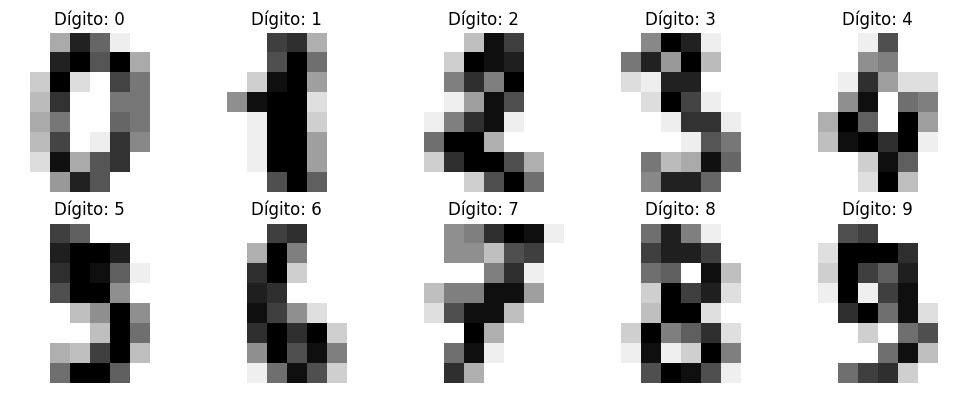

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(
        digits.images[i],
        cmap="gray_r"
    )
    ax.set_title(f"Dígito: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Preguntas:

- ¿Cuántas observaciones y variables predictoras tiene el conjunto de datos?

    **R:** 1797 observaciones y 64 variables predictoras.

- ¿Cuántas clases diferentes existen?

    **R:** 3

- ¿Por qué cada observación tiene 64 características si originalmente es una imagen?

    **R:** Porque cada pixel es una característica. 

- ¿Las clases están aproximadamente balanceadas?

    **R:** Sí.


**Parte 2. Entrenamiento de una SVM multiclase.** Divide los datos en entrenamiento (70 %) y prueba (30 %), utilizando stratify=y y random_state=42.

Construye un Pipeline que incluya:

- StandardScaler().
- SVC(kernel="linear", C=1).

Entrena el modelo y evalúa su exactitud sobre los conjuntos de entrenamiento y prueba.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [19]:
modelo = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="linear",
            C=1
        )
    )
])

modelo.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,64
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [20]:
pred_train = modelo.predict(
    X_train
)

ac_train = accuracy_score(
    y_train,
    pred_train
)

In [21]:
pred_test = modelo.predict(
    X_test
)

ac_test = accuracy_score(
    y_test,
    pred_test
)

In [22]:
tabla_resultado = {
    "Conjunto": ["Train", "Test"],
    "Accuracy": [ac_train, ac_test]
}

tabla_resultado = pd.DataFrame(
    tabla_resultado
)

tabla_resultado

,Conjunto,Accuracy
0,Train,1.00000
1,Test,0.97963


Preguntas:

- ¿Qué exactitud obtuviste en entrenamiento y prueba?

    **R:** 1 y 0.97

- ¿Cuántos clasificadores binarios entrena internamente SVC para este problema?

    **R:** 3(2)/2 = 3

- ¿Por qué no necesitamos construir manualmente un clasificador para cada par de dígitos?

    **R:** Porque ya lo hace internamente.


**Parte 3. Comparación con un kernel RBF.** Construye una segunda SVM utilizando un kernel RBF.

Utiliza inicialmente:

SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

Compara su desempeño con el modelo lineal.

In [23]:
modelo2 = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="rbf",
            C=1,
            gamma="scale"
        )
    )
])

modelo2.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,64
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [24]:
pred_test2 = modelo2.predict(
    X_test
)

ac_test2 = accuracy_score(
    y_test,
    pred_test2
)

In [25]:
tabla_resultado2 = {
    "Modelo": ["Lineal", "RBF"],
    "Accuracy_test": [ac_test, ac_test2]
}

tabla_resultado2 = pd.DataFrame(
    tabla_resultado2
)

tabla_resultado2

,Modelo,Accuracy_test
0,Lineal,0.979630
1,RBF,0.983333


- ¿Qué modelo obtuvo mayor exactitud en el conjunto de prueba?

    **R:** RBF

- ¿Existe una diferencia importante entre ambos resultados?

    **R:** No.

- ¿Qué ventaja podría ofrecer un kernel RBF para reconocer dígitos escritos a mano?

    **R:** Los digitos normalmente no se escriben de manera recta.

- ¿Podemos concluir que el modelo más complejo siempre será mejor?

    **R:** No.


**Parte 4. Selección de hiperparámetros.** Utiliza GridSearchCV para seleccionar los hiperparámetros de la SVM con kernel RBF.

Considera:

$$
C \in {0.1, 1, 10, 100}
$$

y

$$
\gamma \in {0.001, 0.01, 0.1}.
$$

Utiliza validación cruzada estratificada de 3 pliegues y accuracy como métrica de evaluación.

Realiza la búsqueda únicamente sobre los datos de entrenamiento y utiliza n_jobs=2 para limitar el paralelismo.

In [26]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [27]:
pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC()
    )
])

param_grid_rbf = {
    "svc__kernel": ["rbf"],
    "svc__C": [
        0.1,
        1,
        10,
        100
    ],
    "svc__gamma": [
        0.001,
        0.01,
        0.1
    ]
}

In [28]:
grid_rbf = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid_rbf,
    cv=cv,
    scoring="accuracy",
    n_jobs=2
)

In [29]:
grid_rbf.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.1, 1, ...], 'svc__gamma': [0.001, 0.01, ...], 'svc__kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [30]:
grid_rbf.best_params_

{'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}

In [31]:
grid_rbf.best_score_

np.float64(0.973747016706444)

Preguntas:

- ¿Cuántas combinaciones de hiperparámetros se evaluarán?

    **R:** 4 x 3 = 12

- ¿Cuántos ajustes se realizarán durante la validación cruzada?

    **R:** 12 x 3 = 36

- ¿Qué combinación de $C$ y $\gamma$ obtuvo el mejor desempeño promedio?

    **R:** C = 10 y gamma igual a 0.01

- ¿La búsqueda mejoró el resultado obtenido inicialmente con el kernel RBF?

    **R:** Más o menos.

- ¿El mejor modelo supera a la SVM lineal?

    **R:** Sí.



In [32]:
mejor_modelo = grid_rbf.best_estimator_

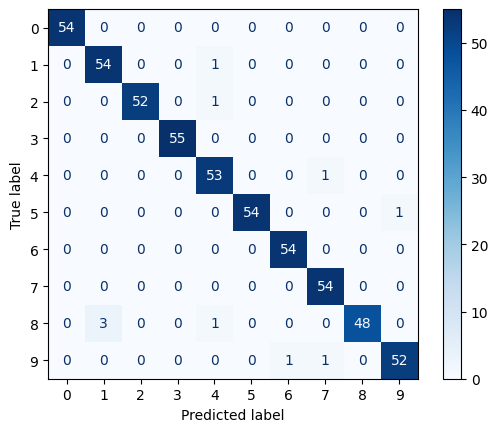

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo,
    X_test,
    y_test,
    cmap="Blues"
)

plt.show()

Preguntas:

- ¿Qué dígitos se clasifican correctamente con mayor frecuencia?

**R:** El 0, el 3, el 6 y el 7.

- ¿Qué pares de dígitos se confunden más?

**R:** El 8 y el 1.

- ¿Por qué algunos dígitos podrían resultar más difíciles de distinguir?

**R:** Por la manera de escribir.

- ¿Qué información adicional proporciona la matriz de confusión que no podemos obtener únicamente con accuracy?

**R:** La matriz nos dice cómo y en dónde se equivoca el modelo.